# Exploring motion gating and keyframe extraction

This notebook runs the two scripts on one video and shows what they found:

1. **`motion_gating.py`**: when does something move?
2. **`keyframes.py`**: which few frames represent each moving part?

The [README](README.md) explains how each step works. Change parameters in the config cell, then *Run All*.
The slow part (decoding the video, ~50 s) is cached, so later re-runs are much faster.

In [1]:
import base64, time
from pathlib import Path

import cv2
import matplotlib
matplotlib.use("Agg")  # draw figures without a screen; we embed them as images below
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, Markdown, display

import keyframes as kfx           # stage 2
import motion_gating as mg        # stage 1
import visualize as viz           # drawing helpers
from video_utils import format_hms, video_info

pd.set_option("display.precision", 3)
T0 = time.perf_counter()
TIMINGS = {}

def show_fig(fig):
    display(Image(viz.fig_png_bytes(fig)))
    plt.close(fig)

def show_img(img, quality=70):
    display(Image(viz.jpeg_bytes(img, quality)))

## Config
Same defaults as in the scripts. Edit here to experiment.

In [2]:
VIDEO = Path("video/meva_30min.mp4")   # any video works

SCAN = dict(                # stage 1, slow pass (changing these re-decodes the video, ~1 min)
    sample_fps=5.0,         # frames analysed per second of video
    width=320,              # analysis width in pixels
    blur_ksize=5,           # blur to suppress pixel noise
    diff_threshold=15,      # frame differencing: grey-level change that counts as motion
    mog2_history=500,       # MOG2 memory in samples (500 = 100 s)
    mog2_var_threshold=16.0,
    mog2_learning_rate=-1.0,
    mog2_illum_ncc=0.7,     # lighting filter (None = off)
    morph_kernel=3,         # noise clean-up size
    ignore_polygons=[],     # e.g. [[(0, 0), (1, 0), (1, 0.22), (0, 0.22)]] ignores the top 22% (sky)
    hash_grid=4, hist_bins=32,
)
SEGMENTS = dict(            # stage 1, cheap
    method="mog2",          # score used for segments + keyframes: "mog2" or "diff"
    threshold_mode="adaptive", k=3.0, floor=0.001,
    fixed_threshold={"mog2": 0.004, "diff": 0.006},
    stop_ratio=0.5, smooth_s=1.0, merge_gap_s=3.0, min_duration_s=1.0, pad_s=2.0,
)
KEYFRAMES = dict(           # stage 2, cheap
    metric="phash", change_threshold=6.0, dedup_threshold=2.5,
    min_gap_s=3.0, max_gap_s=30.0, heartbeat_s=300.0,
)
NAIVE_FPS = 1.0             # baseline for comparison: "just take 1 frame per second"

TOP_N = 10                  # segments shown in detail
N_GIFS = 3
THUMB_W = 160
SWEEP_K = np.arange(1.0, 8.01, 0.5)

OUT = mg.output_dir(VIDEO)
print("video:", VIDEO, "| outputs:", OUT)

video: video\meva_30min.mp4 | outputs: C:\rewind\meva\outputs\meva_30min


## 1. The video
One frame per minute, to get a feel for the scene.

,value
duration,00:30:01.233
fps,30.0
frames,54037
resolution,1280x720


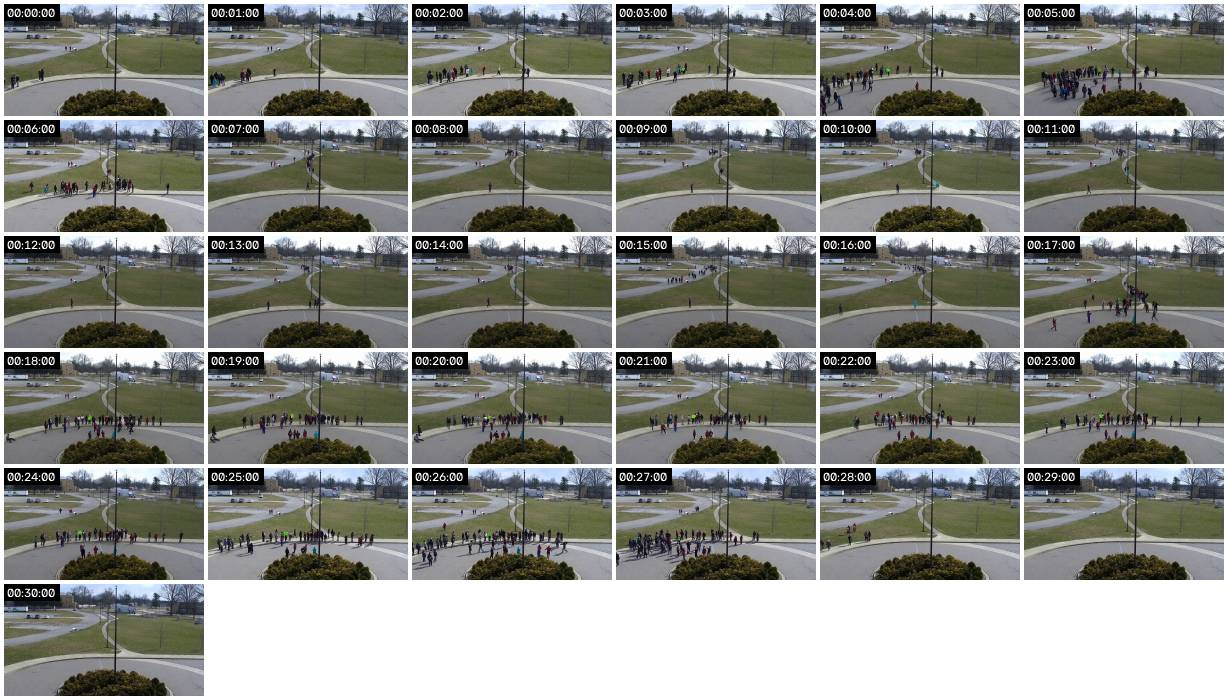

In [3]:
info = video_info(VIDEO)
D = info.duration_s
display(pd.Series({"duration": format_hms(D), "fps": info.fps, "frames": info.frame_count,
                   "resolution": f"{info.width}x{info.height}"}).to_frame("value"))
t0 = time.perf_counter()
show_img(viz.contact_sheet(VIDEO, info.fps, np.arange(0, D, 60)))
TIMINGS["contact sheet"] = time.perf_counter() - t0

## 2. Run stage 1: motion gating

In [4]:
t0 = time.perf_counter()
scan = mg.scan_video(VIDEO, **SCAN, cache_dir=OUT / "cache")
TIMINGS["stage 1: decode + motion scores"] = time.perf_counter() - t0
scores, sig, st = scan["scores"], scan["sig"], scan["stats"]
print(f"{'loaded from cache' if st['from_cache'] else 'decoded'}: {st['frames_decoded']} frames, "
      f"{st['samples']} analysed (every {st['step']}th). Decode pass: {st['scan_s']:.1f} s = "
      f"{st['decoded_fps']:.0f} frames/s, {st['samples_per_s']:.0f} analysed frames/s")

t0 = time.perf_counter()
RESULTS = mg.segment_both_methods(scores, D, **SEGMENTS)
TIMINGS["stage 1: thresholds + segments"] = time.perf_counter() - t0
METHOD = SEGMENTS["method"]
segments = RESULTS[METHOD]["segments"]
mg.save_results(OUT, scores, RESULTS, METHOD)
for m, r in RESULTS.items():
    print(f"{m:5s}: start {r['start']*100:.2f}%  stop {r['stop']*100:.2f}%  -> {len(r['segments'])} segments, "
          f"{mg.active_fraction(r['segments'], D):.1%} of video active" + ("   <- used" if m == METHOD else ""))

decoded: 54037 frames, 9007 analysed (every 6th). Decode pass: 47.0 s = 1151 frames/s, 192 analysed frames/s
diff : start 0.66%  stop 0.33%  -> 7 segments, 22.1% of video active
mog2 : start 0.32%  stop 0.16%  -> 10 segments, 21.9% of video active   <- used


## 3. Run stage 2: keyframes

In [5]:
t0 = time.perf_counter()
KF = {m: kfx.select_keyframes(scores, RESULTS[m]["segments"], sig, score_col=RESULTS[m]["col"], **KEYFRAMES)
      for m in ("diff", "mog2")}
TIMINGS["stage 2: select keyframes"] = time.perf_counter() - t0
t0 = time.perf_counter()
kf = kfx.export_keyframes(VIDEO, KF[METHOD], OUT)
TIMINGS["stage 2: save JPGs"] = time.perf_counter() - t0
print(f"{len(kf)} keyframes: {kf['reason'].value_counts().to_dict()}")
kf.drop(columns="sample").head()

109 keyframes: {'change': 86, 'peak': 10, 'first': 9, 'heartbeat': 4}


,filename,frame_idx,timestamp_s,timestamp_hms,segment_id,motion_score,reason
0,kf_00-00-00.000_idle.jpg,0,0.0,00:00:00.000,-1,0.000,heartbeat
1,kf_00-01-46.000_seg000.jpg,3180,106.0,00:01:46.000,0,0.002,first
2,kf_00-01-48.200_seg000.jpg,3246,108.2,00:01:48.200,0,0.004,peak
3,kf_00-01-52.000_seg000.jpg,3360,112.0,00:01:52.000,0,0.002,change
4,kf_00-03-50.800_seg001.jpg,6924,230.8,00:03:50.800,1,0.002,first


## 4. Timeline
How to read it: the blue line is the motion score (% of pixels moving). Above the red dashed line a segment *starts*,
below the orange dotted line it *stops*. Shaded areas are the segments, and the ticks under the axis are keyframes coloured by reason
(blue first · red peak · green change · purple maxgap · grey heartbeat).

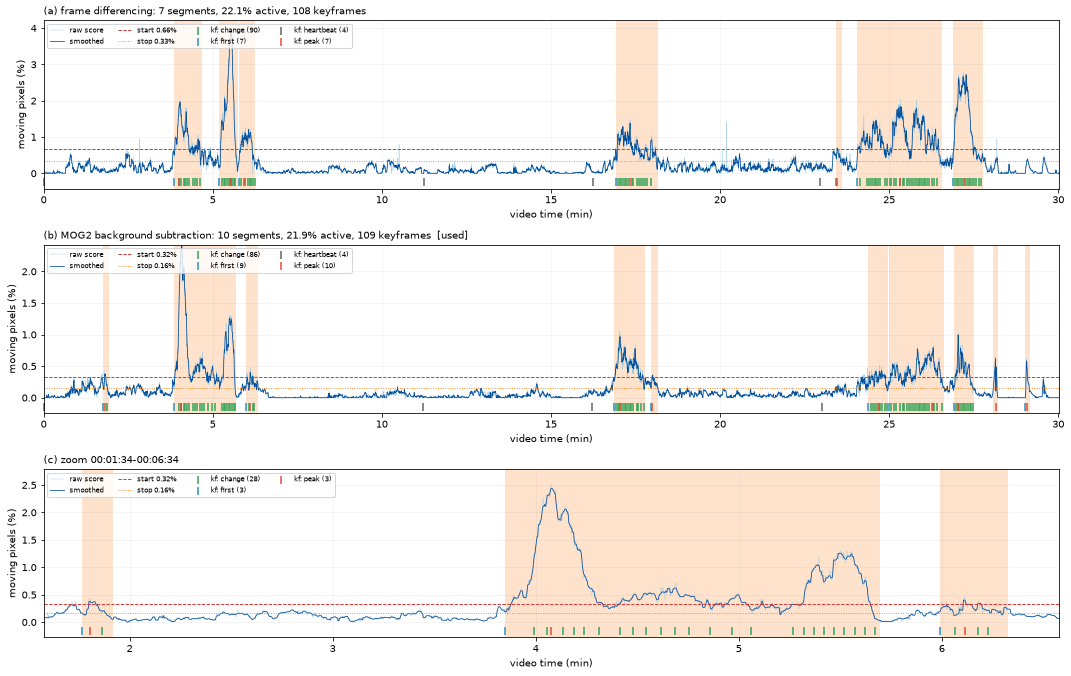

In [6]:
SMOOTH_WIN = max(1, round(SEGMENTS["smooth_s"] * st["effective_sample_fps"]))
fig, axes = plt.subplots(3, 1, figsize=(15, 9.5))
names = {"diff": "(a) frame differencing", "mog2": "(b) MOG2 background subtraction"}
for ax, m in zip(axes[:2], ("diff", "mog2")):
    r = RESULTS[m]
    viz.plot_timeline(ax, scores, r["col"], r["segments"], r["start"], r["stop"], SMOOTH_WIN, KF[m],
                      f"{names[m]}: {len(r['segments'])} segments, {mg.active_fraction(r['segments'], D):.1%} active, "
                      f"{len(KF[m])} keyframes" + ("  [used]" if m == METHOD else ""))
    ax.legend(loc="upper left", fontsize=7, ncol=4)
# zoom: 5 minutes around the strongest segment
top = segments.loc[segments["peak_score"].idxmax()]
z0 = max(0, top["peak_time_s"] - 150); z1 = min(D, z0 + 300)
r = RESULTS[METHOD]
viz.plot_timeline(axes[2], scores[scores.timestamp_s.between(z0, z1)], r["col"],
                  segments[(segments.end_s > z0) & (segments.start_s < z1)], r["start"], r["stop"], SMOOTH_WIN,
                  kf[kf.timestamp_s.between(z0, z1)], f"(c) zoom {format_hms(z0)[:8]}-{format_hms(z1)[:8]}")
axes[2].legend(loc="upper left", fontsize=7, ncol=4)
fig.tight_layout()
show_fig(fig)

Average brightness over time. Clouds change the lighting, which can fool MOG2; that's why the lighting filter exists.

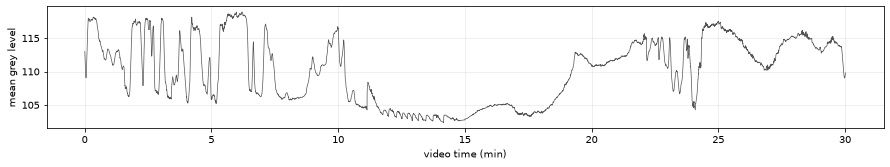

In [7]:
fig, ax = plt.subplots(figsize=(15, 2.2))
ax.plot(scores.timestamp_s / 60, scores.mean_luma, lw=0.7, color="#555")
ax.set(xlabel="video time (min)", ylabel="mean grey level"); ax.grid(alpha=.25)
show_fig(fig)

## 5. Summary: how many frames would an expensive model have to look at?

In [8]:
def summarize(m):
    segs, k = RESULTS[m]["segments"], KF[m]
    naive = int(D * NAIVE_FPS)
    return {"segments": len(segs), "active (% of video)": 100 * mg.active_fraction(segs, D),
            "keyframes": len(k), "keyframes per minute": len(k) / (D / 60),
            f"naive {NAIVE_FPS:g} frame/s": naive, "reduction (x fewer frames)": naive / len(k)}

display(pd.DataFrame({m + (" [used]" if m == METHOD else ""): summarize(m) for m in ("diff", "mog2")}).round(1))
S = summarize(METHOD)
display(Markdown(f"### {S['keyframes']} keyframes instead of {S[f'naive {NAIVE_FPS:g} frame/s']:,} "
                 f"(**{S['reduction (x fewer frames)']:.1f}x fewer**); {S['active (% of video)']:.1f}% of the video is active."))

,diff,mog2 [used]
segments,7.0,10.0
active (% of video),22.1,21.9
keyframes,108.0,109.0
keyframes per minute,3.6,3.6
naive 1 frame/s,1801.0,1801.0
reduction (x fewer frames),16.7,16.5


### 109 keyframes instead of 1,801 (**16.5x fewer**); 21.9% of the video is active.

## 6. Segments
All segments, then the strongest ones: 6 frames spread over the segment, and the peak frame with the MOG2 mask on top
(**red** = moving pixels that count, **yellow** = blobs the lighting filter removed).

In [9]:
segments.assign(peak_pct=segments.peak_score * 100,
                keyframes=segments.segment_id.map(kf.segment_id.value_counts()).fillna(0).astype(int)
                )[["segment_id", "start_hms", "end_hms", "duration_s", "peak_pct", "keyframes"]]

,segment_id,start_hms,end_hms,duration_s,peak_pct,keyframes
0,0,00:01:46.000,00:01:55.200,9.2,0.438,3
1,1,00:03:50.800,00:05:41.800,111.0,2.507,26
2,2,00:05:59.400,00:06:19.600,20.2,0.474,5
3,3,00:16:51.600,00:17:46.800,55.2,1.056,17
4,4,00:17:57.800,00:18:10.800,13.0,0.363,2
5,5,00:24:22.200,00:24:57.200,35.0,0.516,11
6,6,00:25:00.600,00:26:37.800,97.2,0.821,25
7,7,00:26:55.200,00:27:30.000,34.8,1.028,13
8,8,00:28:04.600,00:28:13.200,8.6,0.658,1
9,9,00:29:01.000,00:29:10.600,9.6,0.616,2


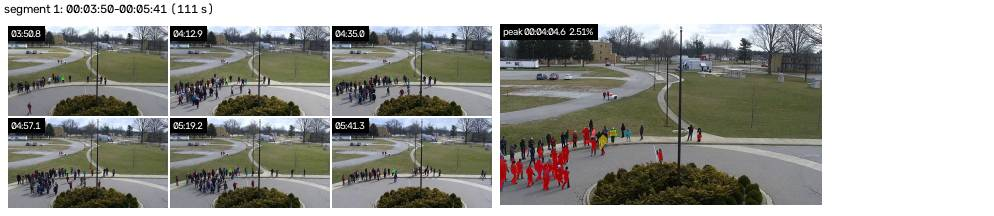

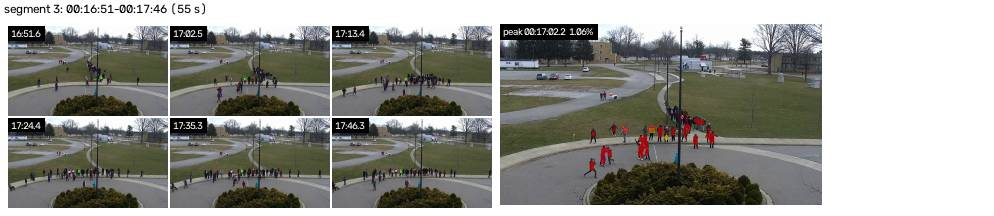

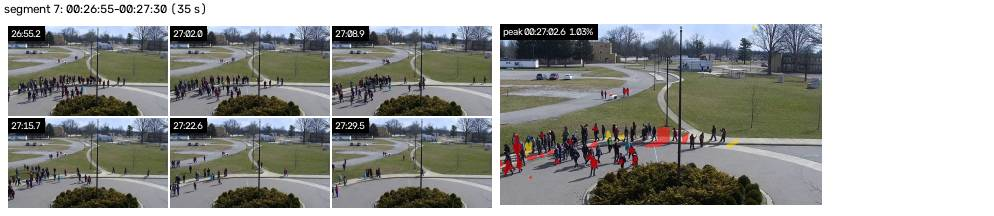

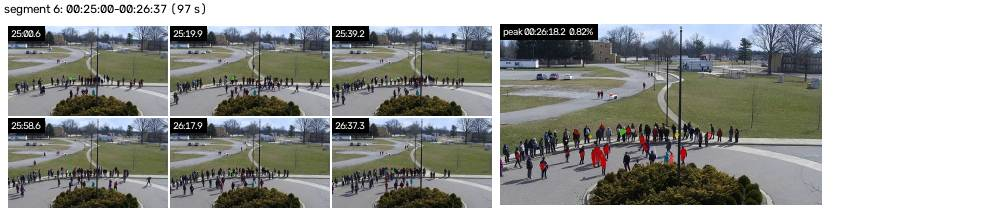

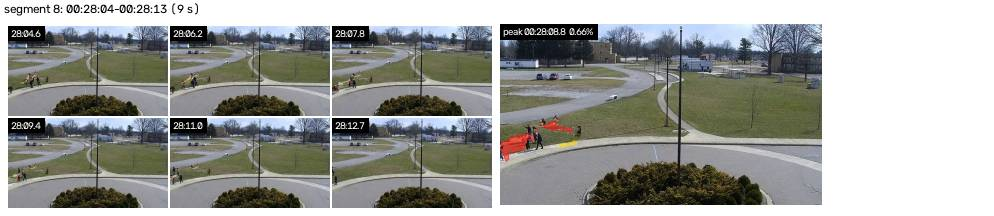

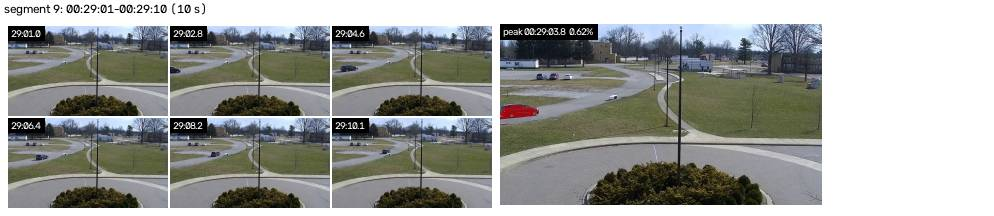

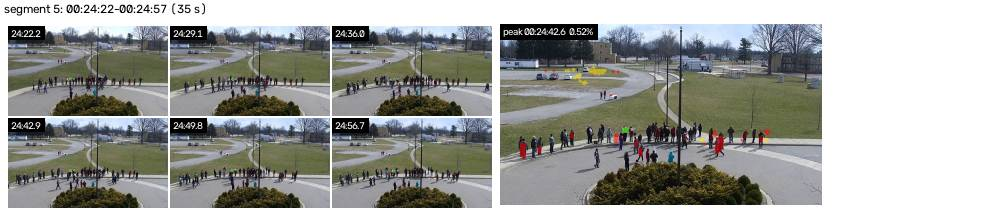

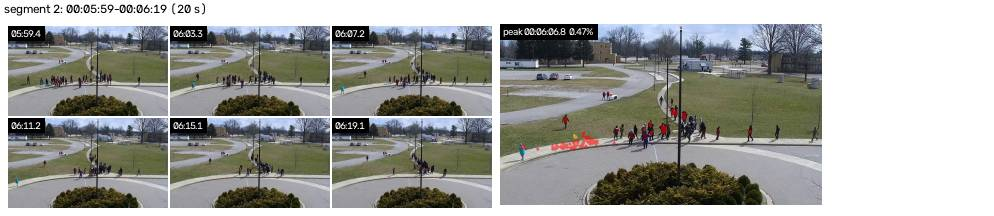

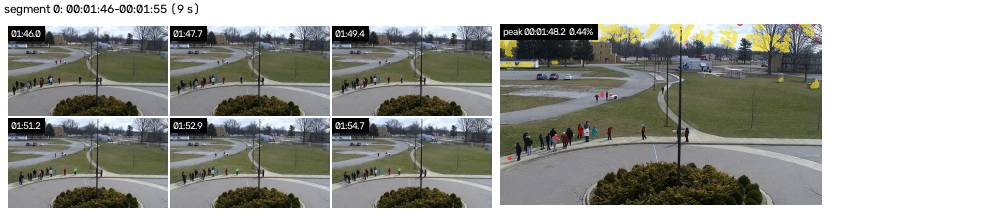

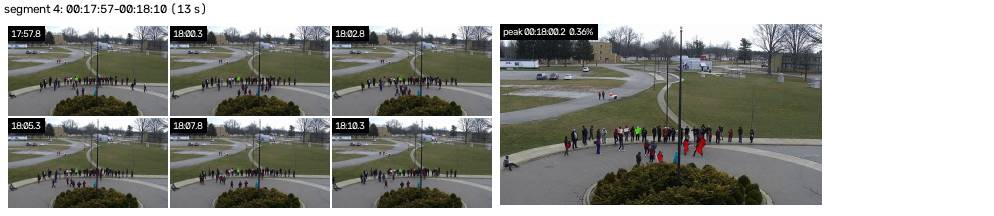

In [10]:
t0 = time.perf_counter()
top_segs = segments.nlargest(TOP_N, "peak_score")
strip_idx = {s.segment_id: [int(round(t * info.fps)) for t in np.linspace(s.start_s, s.end_s - 0.5, 6)]
             for s in top_segs.itertuples()}
frames = viz.frames_at(VIDEO, [i for v in strip_idx.values() for i in v])
for s in top_segs.itertuples():
    strip = viz.grid([viz.label(viz.thumb(frames[i], THUMB_W), format_hms(i / info.fps)[3:10], scale=0.35)
                      for i in strip_idx[s.segment_id]], cols=3, pad=2)
    peak, mask, removed = mg.foreground_mask_at(VIDEO, s.peak_frame_idx, scan["params"], "mog2")
    ov = viz.label(viz.thumb(viz.overlay_mask(peak, mask, removed=removed), 2 * THUMB_W + 2),
                   f"peak {format_hms(s.peak_time_s)[:10]}  {s.peak_score*100:.2f}%", scale=0.35)
    row = viz.grid([strip, ov], cols=2, pad=6)
    head = np.full((18, row.shape[1], 3), 255, np.uint8)
    cv2.putText(head, f"segment {s.segment_id}: {s.start_hms[:8]}-{s.end_hms[:8]} ({s.duration_s:.0f} s)",
                (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 1, cv2.LINE_AA)
    show_img(np.vstack([head, row]))
TIMINGS["figures: top segments"] = time.perf_counter() - t0

## 7. Animated previews
Low-res GIFs at 5x speed (20 s of video in 4 s).


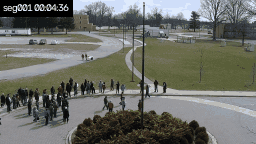
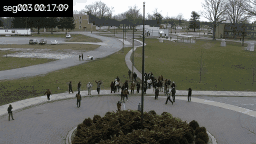
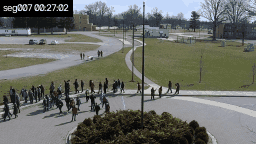

In [11]:
t0 = time.perf_counter()
html = []
for s in segments.nlargest(N_GIFS, "peak_score").sort_values("start_s").itertuples():
    p, size, speed = viz.segment_gif(VIDEO, info.fps, s.start_s, s.end_s, OUT / "gifs" / f"seg{s.segment_id:03d}.gif",
                                     caption=f"seg{s.segment_id:03d}")
    b64 = base64.b64encode(p.read_bytes()).decode()
    html.append(f'<figure style="display:inline-block;margin:4px"><img src="data:image/gif;base64,{b64}" width="256">'
                f'<figcaption style="font-size:11px">segment {s.segment_id}, {s.start_hms[:8]}-{s.end_hms[:8]}, '
                f'{speed:.0f}x, {size/1e3:.0f} KB</figcaption></figure>')
display(HTML("".join(html)))
TIMINGS["figures: GIFs"] = time.perf_counter() - t0

## 8. All keyframes
Timestamp and segment on top, reason at the bottom, border colour = reason. Full-size files are in `outputs/<video>/keyframes/`.

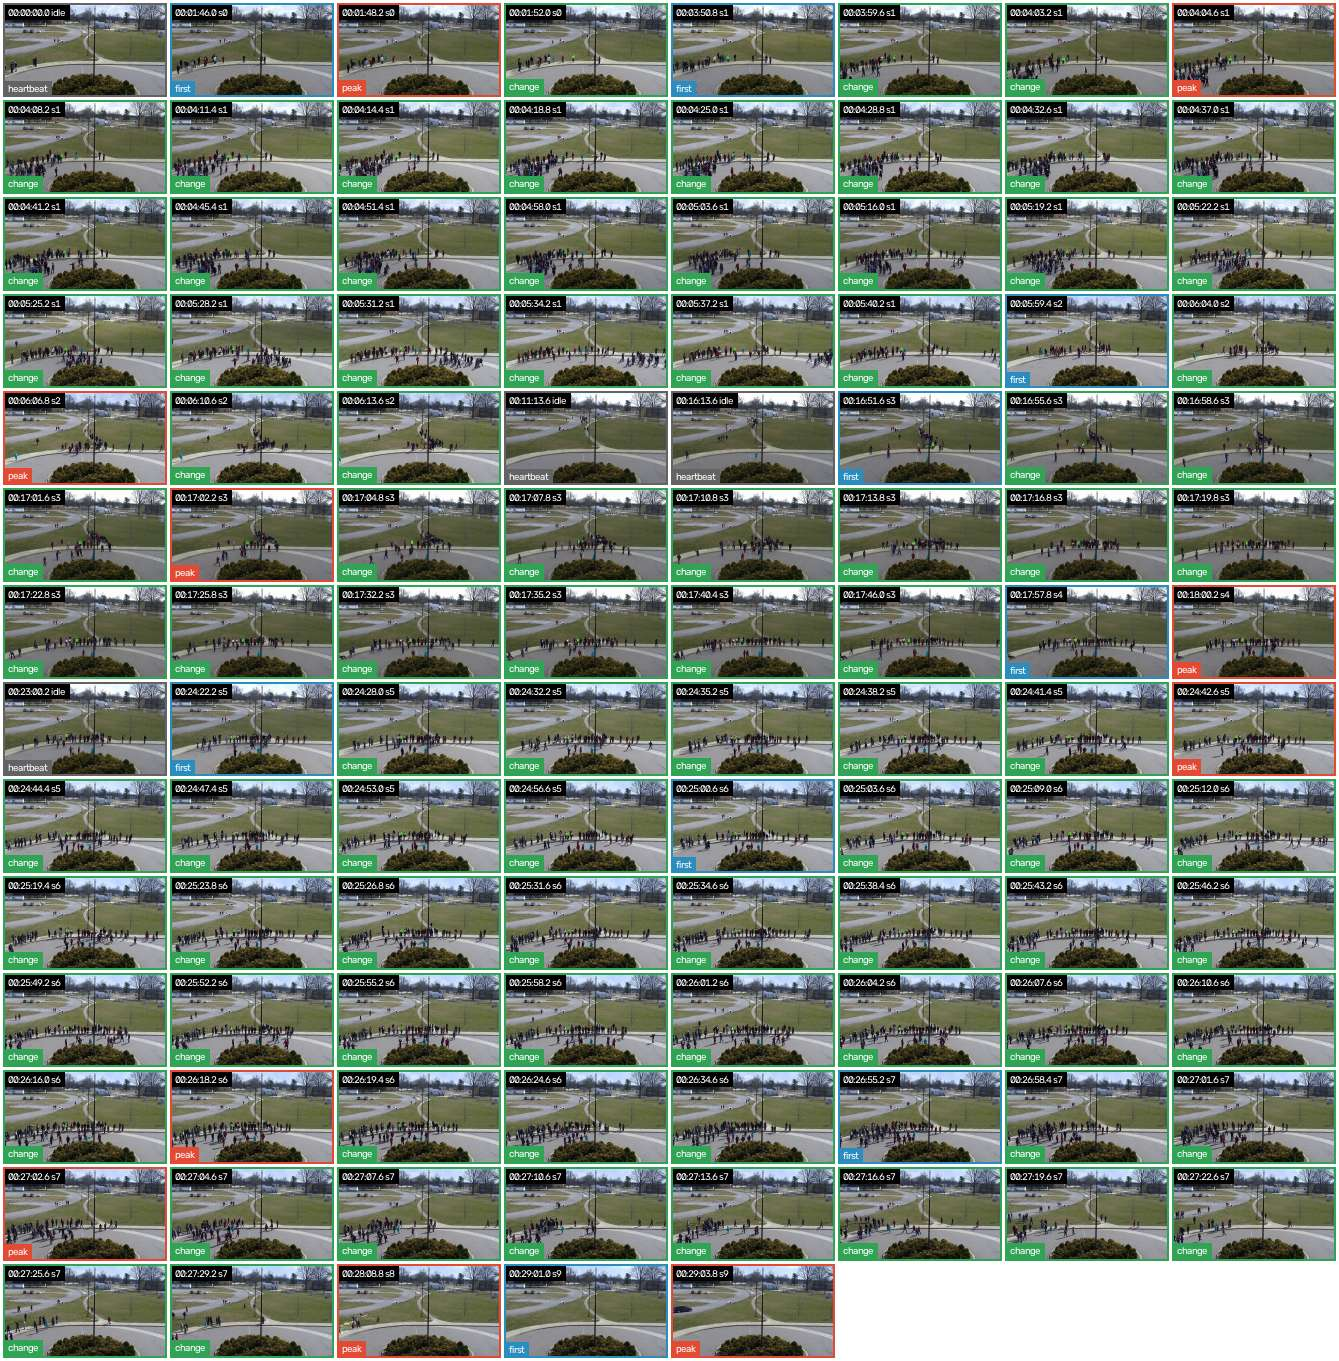

In [12]:
t0 = time.perf_counter()
tiles = []
for r in kf.itertuples():
    col = viz.hex_to_bgr(viz.REASON_COLORS[r.reason])
    t = viz.label(viz.thumb(cv2.imread(str(OUT / "keyframes" / r.filename)), THUMB_W),
                  f"{r.timestamp_hms[:10]} " + ("idle" if r.segment_id < 0 else f"s{r.segment_id}"), scale=0.33)
    tiles.append(viz.border(viz.label(t, r.reason, pos="bottom", scale=0.33, bg=col), col, 2))
show_img(viz.grid(tiles, cols=8, pad=3), quality=60)
TIMINGS["figures: gallery"] = time.perf_counter() - t0

## 9. Sanity checks
**(a)** Random frames from *inactive* time: did we skip anything important?
**(b)** Suspicious segments (shorter than 8 s, or a peak barely above the threshold), worth a manual look.

(a) 78% of samples are inactive. Random examples:


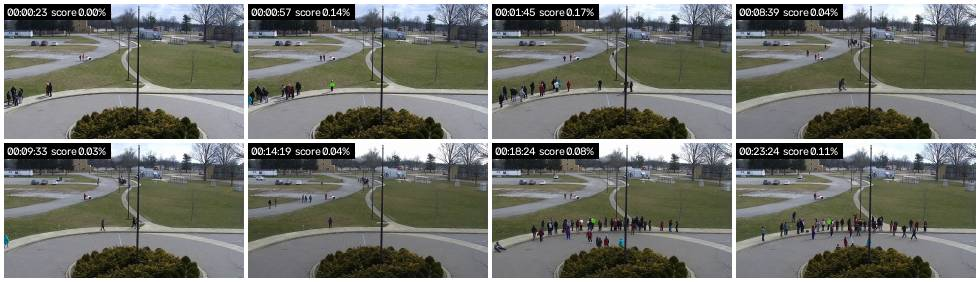

In [13]:
rng = np.random.default_rng(0)
t_all = scores.timestamp_s.to_numpy()
idle = np.flatnonzero(~mg.active_mask(t_all, segments))
pick = np.sort(rng.choice(idle, size=min(8, idle.size), replace=False))
fr = viz.frames_at(VIDEO, scores.frame_idx.to_numpy()[pick])
print(f"(a) {idle.size / len(t_all):.0%} of samples are inactive. Random examples:")
show_img(viz.grid([viz.label(viz.thumb(fr[scores.frame_idx.iat[i]], 240),
                             f"{format_hms(t_all[i])[:8]}  score {scores[RESULTS[METHOD]['col']].iat[i]*100:.2f}%", scale=0.38)
                   for i in pick], cols=4))

(b) 3 suspicious segment(s)


,segment_id,start_hms,duration_s,peak_pct,why
0,0,00:01:46.000,9.2,0.438,low-peak
2,2,00:05:59.400,20.2,0.474,low-peak
4,4,00:17:57.800,13.0,0.363,low-peak


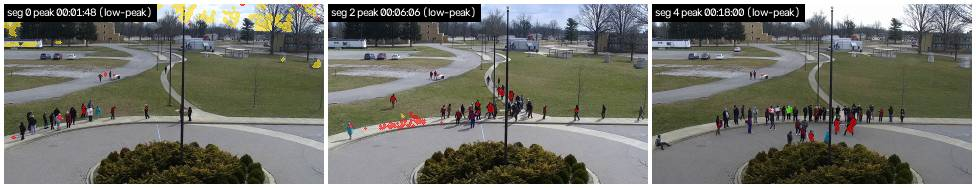

In [14]:
thr = RESULTS[METHOD]["start"]
sus = segments[(segments.duration_s < 8) | (segments.peak_score < 1.5 * thr)].copy()
sus["why"] = np.where(sus.duration_s < 8, "short ", "") + np.where(sus.peak_score < 1.5 * thr, "low-peak", "")
print(f"(b) {len(sus)} suspicious segment(s)")
if len(sus):
    display(sus.assign(peak_pct=sus.peak_score * 100)[["segment_id", "start_hms", "duration_s", "peak_pct", "why"]])
    tiles = []
    for s in sus.itertuples():
        f, mk, rm = mg.foreground_mask_at(VIDEO, s.peak_frame_idx, scan["params"], "mog2")
        tiles.append(viz.label(viz.thumb(viz.overlay_mask(f, mk, removed=rm), 320),
                               f"seg {s.segment_id} peak {format_hms(s.peak_time_s)[:8]} ({s.why.strip()})", scale=0.38))
    show_img(viz.grid(tiles, cols=3))

## 10. Sensitivity sweep
How % active and keyframe count change with the threshold (adaptive `k` from 1 to 8). Uses the cached scan, so it's fast.

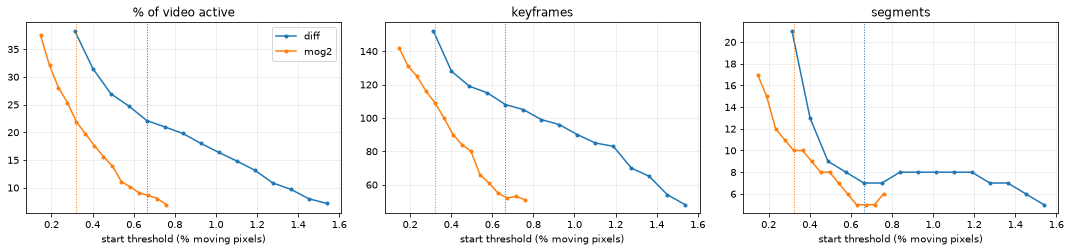

In [15]:
t0 = time.perf_counter()
rows = []
for m in ("diff", "mog2"):
    for k_ in SWEEP_K:
        p = dict(SEGMENTS, k=k_, threshold_mode="adaptive")
        start, stop = mg.start_stop_thresholds(scores, m, **p)
        segs = mg.find_segments(scores, f"score_{m}", start_threshold=start, stop_threshold=stop, duration_s=D,
                                **{x: p[x] for x in ("smooth_s", "merge_gap_s", "min_duration_s", "pad_s")})
        n_kf = len(kfx.select_keyframes(scores, segs, sig, score_col=f"score_{m}", **KEYFRAMES))
        rows.append({"method": m, "k": k_, "threshold_pct": 100 * start, "active_pct": 100 * mg.active_fraction(segs, D),
                     "segments": len(segs), "keyframes": n_kf})
sweep = pd.DataFrame(rows)
TIMINGS["sensitivity sweep"] = time.perf_counter() - t0

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for m, g in sweep.groupby("method"):
    for ax, col in zip(axes, ("active_pct", "keyframes", "segments")):
        ax.plot(g.threshold_pct, g[col], marker="o", ms=3, label=m)
        ax.axvline(RESULTS[m]["start"] * 100, color=ax.lines[-1].get_color(), ls=":", lw=1)  # current setting
for ax, t_ in zip(axes, ("% of video active", "keyframes", "segments")):
    ax.set(xlabel="start threshold (% moving pixels)", title=t_); ax.grid(alpha=.25)
axes[0].legend()
fig.tight_layout()
show_fig(fig)

## Run times

In [16]:
TIMINGS["whole notebook"] = time.perf_counter() - T0
display(pd.Series(TIMINGS, name="seconds").round(2).to_frame())
print(f"keyframe saving: {len(kf) / TIMINGS['stage 2: save JPGs']:.1f} keyframes/s")

,seconds
contact sheet,1.95
stage 1: decode + motion scores,47.08
stage 1: thresholds + segments,0.01
stage 2: select keyframes,0.02
stage 2: save JPGs,4.63
figures: top segments,18.89
figures: GIFs,1.15
figures: gallery,1.07
sensitivity sweep,0.36
whole notebook,81.53


keyframe saving: 23.5 keyframes/s
